# Lab-3

## Classification with K-means clustering and Hyper-parameter optimization using grid search.

### 1st we import all the libraries that are used in all tasks

In [1]:
import pandas as pd  # Import the pandas library for data manipulation and analysis
import numpy as np  # Import NumPy for efficient numerical operations
import matplotlib.pyplot as plt  # Import the Matplotlib library for plotting graphs
from sklearn.metrics import silhouette_score  # Import silhouette score for evaluating clustering performance
from itertools import product  # Import product for generating Cartesian products of input iterables
from sklearn.cluster import KMeans  # Import KMeans for performing k-means clustering

## Task-1: Classification with K-means

### 1.1: Load the new dataset found in the canvas page for this Lab: rent_vs_inc.csv the same way you did in the last lab. What information can you get by just looking at the table?

In [3]:
# Load the dataset into a pandas DataFrame
data = pd.read_csv('inc_vs_rent.csv')

# Display the first few rows of the dataset
data.head()  # This will show the top 5 rows of the DataFrame


### 1.2: Start by creating a scatter plot for your points.

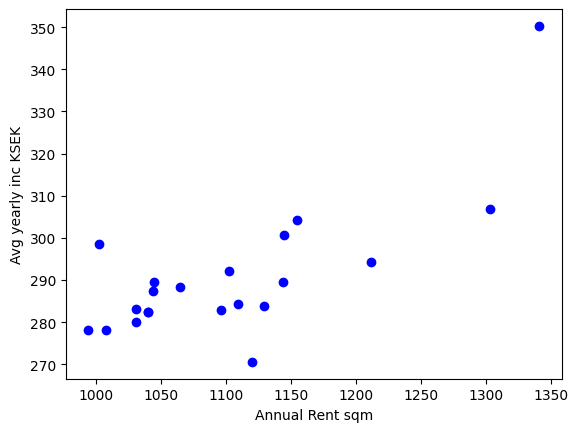

In [11]:
# Create a scatter plot for Annual Rent vs. Avg Yearly Income
plt.scatter(data['Annual rent sqm'], data['Avg yearly inc KSEK'], color='blue')

# Add labels and title (Swapped)
plt.xlabel('Annual Rent sqm')
plt.ylabel('Avg yearly inc KSEK')

# Show the plot
plt.show()


### 1.3: As mentioned in the introduction section you will create your K-means function from scratch.

For information on how to perform K-means can be found in lecture 11:

1.3.1  Initialize the centroids with a starting number of clusters you consider correct, the centroids can be selected as a random point among your sample.

1.3.2  Find which point belongs to which cluster by finding the closer centroid to every point (Euclidean distance).

1.3.3 Calculate the mean point among each cluster to obtain the new centroid

1.3.4  Repeat this process a N (around 10) number of iterations until the mean of the new cluster does not change from the previous iteration.

1.3.5  Create once again a cluster plot with colors assigned for each cluster. For information on how to do this plot, check: https://pythonguides.com/matplotlib-scatter-plot-color/

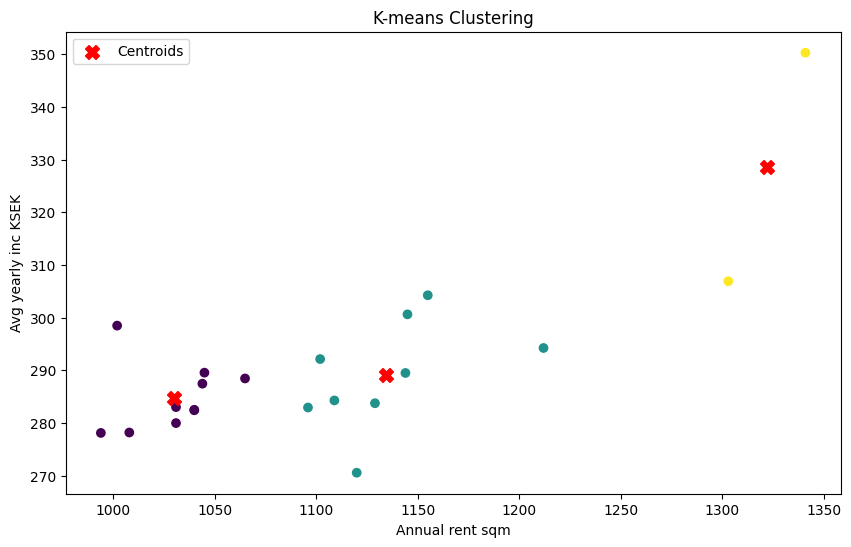

In [12]:
# Function to calculate Euclidean distance
def euclidean_distance(point1, point2):
    """Calculate the Euclidean distance between two points."""
    return np.sqrt(np.sum((point1 - point2) ** 2))  # Compute the square root of the sum of squared differences

# K-means clustering function
def k_means_clustering(data, k, max_iterations=10):
    """Perform K-means clustering on the given data."""
    # Randomly initialize centroids by selecting random samples from the data
    random_indices = np.random.choice(data.shape[0], size=k, replace=False)  # Choose k random indices without replacement
    centroids = data[random_indices]  # Initialize centroids with the selected data points
    
    for _ in range(max_iterations):  # Iterate for a maximum number of iterations
        # Assign clusters based on the closest centroid
        clusters = []  # Initialize an empty list to store cluster assignments
        for point in data:  # Loop through each point in the data
            distances = [euclidean_distance(point, centroid) for centroid in centroids]  # Calculate distance to each centroid
            cluster = np.argmin(distances)  # Get index of the closest centroid
            clusters.append(cluster)  # Assign the cluster index to the point
        
        clusters = np.array(clusters)  # Convert the cluster assignments to a NumPy array
        
        # Update centroids by calculating the mean of the points in each cluster
        new_centroids = np.array([data[clusters == i].mean(axis=0) for i in range(k)])  # Calculate new centroids for each cluster
        
        # Check for convergence (if centroids do not change)
        if np.all(centroids == new_centroids):  # If all centroids remain the same, stop iteration
            break
        
        centroids = new_centroids  # Update centroids for the next iteration

    return centroids, clusters  # Return the final centroids and cluster assignments

# Preparing data for clustering (considering only relevant columns)
data_for_clustering = data[['Annual rent sqm', 'Avg yearly inc KSEK']].values  # Extracting relevant features as a NumPy array

# Run K-means clustering with a specific number of clusters (e.g., k=3)
k = 3  # You can change this value to experiment with different numbers of clusters
centroids, clusters = k_means_clustering(data_for_clustering, k)  # Call the clustering function

# Create a cluster plot with colors assigned for each cluster
plt.figure(figsize=(10, 6))  # Set the figure size for the plot
plt.scatter(data['Annual rent sqm'], data['Avg yearly inc KSEK'], c=clusters, cmap='viridis', marker='o')  # Plot data points with colors based on cluster assignments

# Plot centroids
plt.scatter(centroids[:, 0], centroids[:, 1], c='red', marker='X', s=100, label='Centroids')  # Plot centroids as red 'X' markers

# Add labels and title
plt.xlabel('Annual rent sqm')  # Label for the x-axis
plt.ylabel('Avg yearly inc KSEK')  # Label for the y-axis
plt.title('K-means Clustering')  # Title of the plot
plt.legend()  # Show legend indicating the meaning of colors
plt.show()  # Display the plot


## Task-2: Hyper-parameter optimization

In this task you will implement grid search to find the optimal number of k-means clusters for this
classification task.

### 2.1:  In order to perform the hyper parameter optimization for the number of clusters you will use the silhouette score, for this score create a function that finds the silhouette coefficient for a grid of values between 1 and 10. 

Where:

 ▪ S(i) is the silhouette coefficient of the data point i.

 ▪ a(i) is the average distance between i and all the other data points in the cluster to which i belong. (Intra-cluster distance)

 ▪ b(i) is the average distance from i to all the points in the closest cluster to whichi does not belong. (Inter-cluster distance)

o Create a function a(i) that calculates the average intra-cluster distance from any point i.

o Create a function that calculates the average inter-cluster distance to the closets cluster from datapoint i.

o Create a main function that iterates over all points in the dataset and calculates S(i)

o Perform the grid search obtaining the average S(i) for all points of each cluster value in the grid to get the cluster’s silhouette coefficient. (Iterate over the cluster values between 1 to 10

o Graph the cluster’s silhouette coefficient for each value in the grid to determine the optimal number of clusters for this exercise.


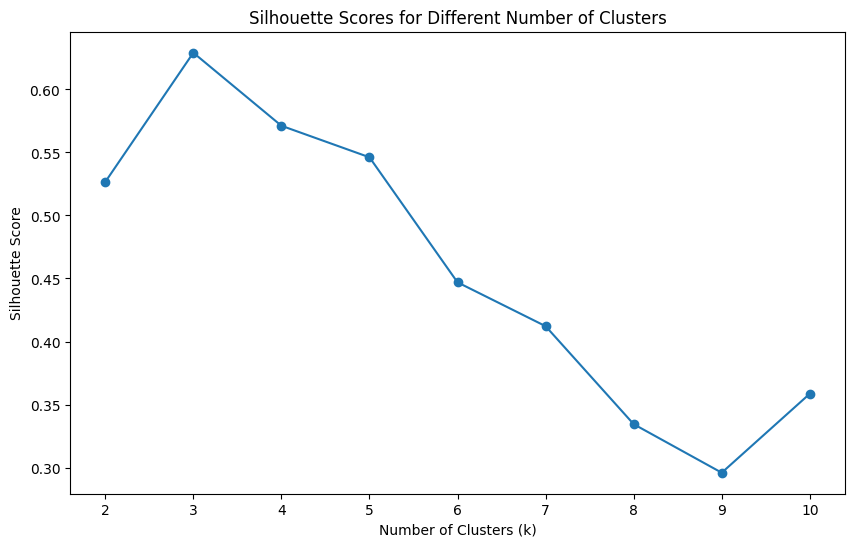

The optimal number of clusters is: 3


In [13]:
# Function to calculate silhouette coefficients
def calculate_silhouette(data, labels):
    """Calculate the silhouette score for given data and cluster labels."""
    return silhouette_score(data, labels)  # Compute and return the silhouette score

# Hyper-parameter optimization using grid search
def grid_search_optimal_k(data, k_min, k_max):
    """Perform grid search to find the optimal number of clusters."""
    silhouette_scores = []  # Initialize a list to store silhouette scores for each k
    
    for k in range(k_min, k_max + 1):  # Iterate over the range of k values
        centroids, clusters = k_means_clustering(data, k)  # Run K-means clustering for the current k
        score = calculate_silhouette(data, clusters)  # Calculate silhouette score for the current clustering
        silhouette_scores.append(score)  # Store the score in the list
    
    return silhouette_scores  # Return the list of silhouette scores

# Range of k values for grid search
k_min = 2  # Minimum number of clusters to consider
k_max = 10  # Maximum number of clusters to consider

# Run grid search to find silhouette scores for the specified range of k
silhouette_scores = grid_search_optimal_k(data_for_clustering, k_min, k_max)

# Plot silhouette scores for each k
plt.figure(figsize=(10, 6))  # Set the figure size for the plot
plt.plot(range(k_min, k_max + 1), silhouette_scores, marker='o')  # Plot silhouette scores against k values
plt.title('Silhouette Scores for Different Number of Clusters')  # Title of the plot
plt.xlabel('Number of Clusters (k)')  # Label for the x-axis
plt.ylabel('Silhouette Score')  # Label for the y-axis
plt.xticks(range(k_min, k_max + 1))  # Set x-ticks for k values
plt.show()  # Display the plot

# Find the optimal number of clusters based on the highest silhouette score
optimal_k = np.argmax(silhouette_scores) + k_min  # Get the index of the maximum score and adjust by adding k_min
print(f'The optimal number of clusters is: {optimal_k}')  # Print the optimal number of clusters


### 2.2: Create a scatter plot with the cluster colors for the newly found optimal number of clusters.

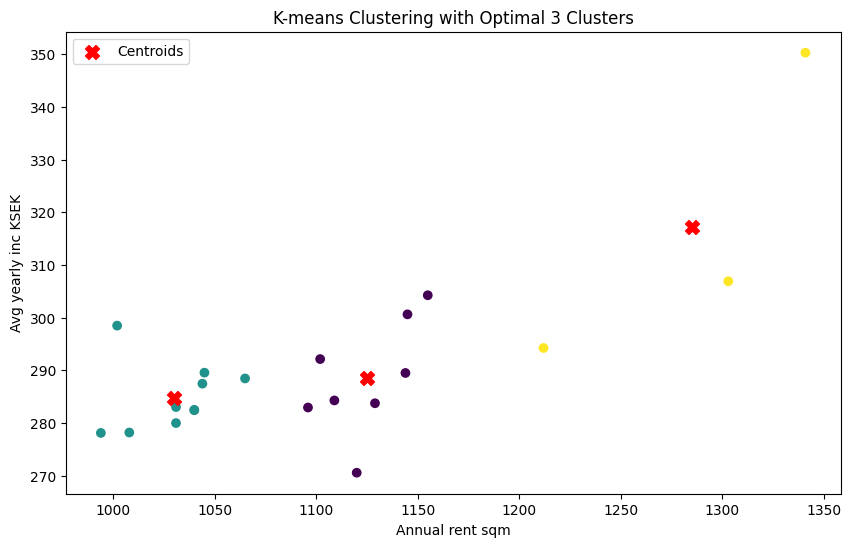

In [14]:
# Running K-means clustering with the optimal number of clusters
centroids, optimal_clusters = k_means_clustering(data_for_clustering, optimal_k)  # Perform K-means clustering with the optimal k value

# Create a scatter plot with colors assigned for each optimal cluster
plt.figure(figsize=(10, 6))  # Set the figure size for the plot
plt.scatter(data['Annual rent sqm'], data['Avg yearly inc KSEK'], c=optimal_clusters, cmap='viridis', marker='o')  
# Plot data points with colors based on the optimal cluster assignments

# Plot centroids
plt.scatter(centroids[:, 0], centroids[:, 1], c='red', marker='X', s=100, label='Centroids')  
# Plot centroids as red 'X' markers, larger size for visibility

# Add labels and title
plt.xlabel('Annual rent sqm')  # Label for the x-axis
plt.ylabel('Avg yearly inc KSEK')  # Label for the y-axis
plt.title(f'K-means Clustering with Optimal {optimal_k} Clusters')  # Title of the plot including the optimal k value
plt.legend()  # Show legend indicating the meaning of colors and markers
plt.show()  # Display the plot


### 2.3: Finally evaluate how your created model predicts new values:

i.  For this task we will assume we have 3 unnamed regions with the following annual rent and average salary [1010, 320.12], [1258, 320], [980, 292.4]

ii. Find which cluster these data points belong to and plot them in the graph.

iii. Based on the cluster graph do you think your model successfully predicted the cluster
for these values?

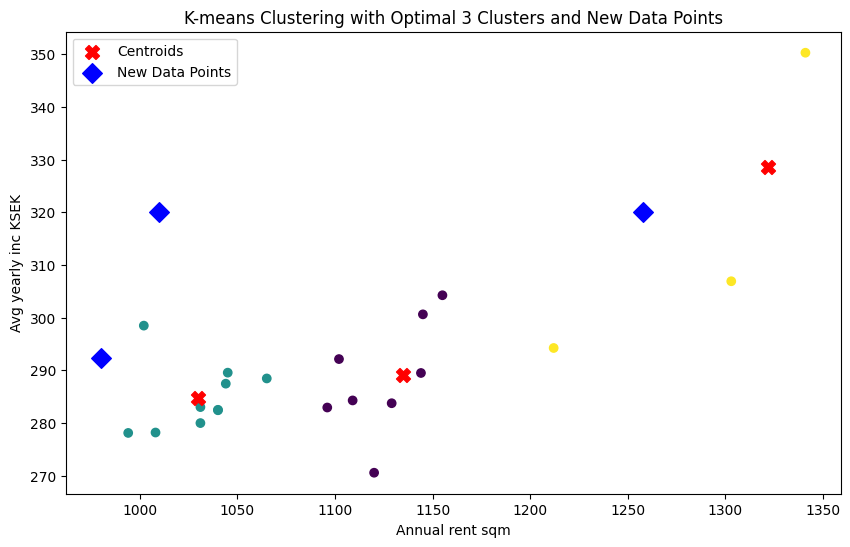

New data point [1010.    320.12] is assigned to cluster 1
New data point [1258.  320.] is assigned to cluster 2
New data point [980.  292.4] is assigned to cluster 1


In [17]:
# New data points to classify
new_data_points = np.array([[1010, 320.12], [1258, 320], [980, 292.4]])  # Define an array of new data points to classify

# Function to assign clusters to new data points using the trained model
def assign_clusters(new_data, centroids):
    """Assign clusters to new data points based on closest centroid."""
    clusters = []  # Initialize an empty list to store cluster assignments
    for point in new_data:  # Loop through each new data point
        distances = [euclidean_distance(point, centroid) for centroid in centroids]  # Calculate distance to each centroid
        cluster = np.argmin(distances)  # Get index of the closest centroid
        clusters.append(cluster)  # Append the cluster index to the list
    return np.array(clusters)  # Return the list as a NumPy array

# Get clusters for new data points
new_clusters = assign_clusters(new_data_points, centroids)  # Assign clusters to the new data points

# Create a scatter plot for new data points
plt.figure(figsize=(10, 6))  # Set the figure size for the plot
plt.scatter(data['Annual rent sqm'], data['Avg yearly inc KSEK'], c=optimal_clusters, cmap='viridis', marker='o')  
# Plot existing data points with colors based on optimal cluster assignments
plt.scatter(centroids[:, 0], centroids[:, 1], c='red', marker='X', s=100, label='Centroids')  
# Plot centroids as red 'X' markers

# Plot new data points
plt.scatter(new_data_points[:, 0], new_data_points[:, 1], c='blue', marker='D', s=100, label='New Data Points')  
# Plot new data points as blue diamond markers

# Add labels and title
plt.xlabel('Annual rent sqm')  # Label for the x-axis
plt.ylabel('Avg yearly inc KSEK')  # Label for the y-axis
plt.title(f'K-means Clustering with Optimal {optimal_k} Clusters and New Data Points')  # Title of the plot
plt.legend()  # Show legend indicating the meaning of colors and markers
plt.show()  # Display the plot

# Print the cluster assignment for new data points
for i, point in enumerate(new_data_points):  # Loop through each new data point
    print(f'New data point {point} is assigned to cluster {new_clusters[i]}')  # Print the assigned cluster


## Optional Task

Can you figure out how to make an N-dimensional grid search optimizer, which can handle an arbitrary
number of hyperparameters to optimize?

Best Silhouette Score: 0.6464284636214762
Best Parameters: {'num_clusters': 3}


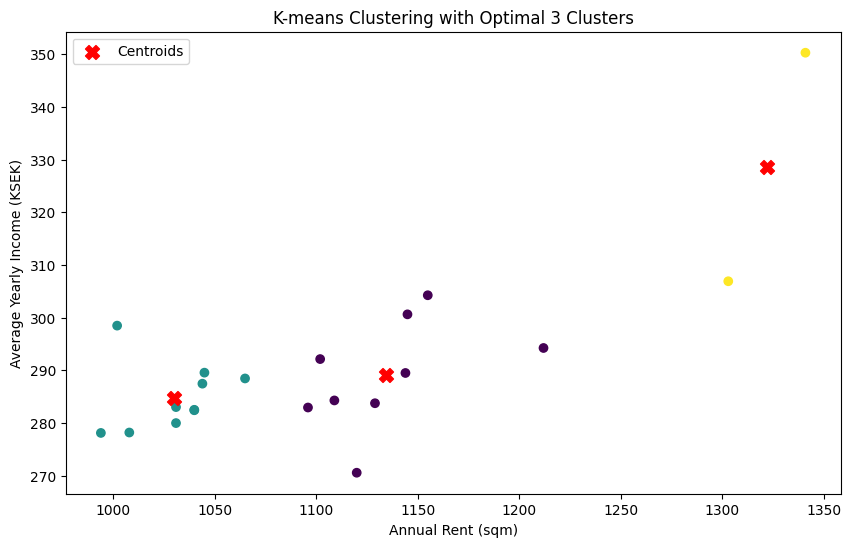

In [16]:
# Load the dataset
data = pd.read_csv('inc_vs_rent.csv')  # Read the CSV file containing the dataset into a pandas DataFrame

# Select features for clustering
data_for_clustering = data[['Annual rent sqm', 'Avg yearly inc KSEK']].values  # Extract relevant features as a NumPy array

# Function to run K-means clustering
def run_k_means(data, n_clusters):
    """Runs K-means clustering on the provided data."""
    kmeans = KMeans(n_clusters=n_clusters, random_state=42)  # Initialize KMeans with specified number of clusters
    kmeans.fit(data)  # Fit the model to the data
    return kmeans.cluster_centers_, kmeans.labels_  # Return the centroids and cluster labels

# Define hyperparameters and their ranges
param_grid = {
    'num_clusters': [2, 3, 4, 5, 6, 7, 8, 9, 10],  # List of different values for the number of clusters to evaluate
    # You can add more hyperparameters here if needed
}

# Generate all combinations of hyperparameters
param_combinations = list(product(*param_grid.values()))  # Create a list of all possible parameter combinations

best_score = -1  # Initialize best score to a low value
best_params = {}  # Dictionary to hold the best parameters

# Loop through each combination
for params in param_combinations:
    num_clusters = params[0]  # Extract the number of clusters from the current parameter combination

    # Apply K-means clustering with the current combination
    centroids, labels = run_k_means(data_for_clustering, num_clusters)  # Run K-means clustering

    # Calculate the silhouette score
    score = silhouette_score(data_for_clustering, labels)  # Compute the silhouette score for the current clustering

    # Check if this is the best score
    if score > best_score:  # If the current score is better than the best score found so far
        best_score = score  # Update best score
        best_params = {'num_clusters': num_clusters}  # Update best parameters

# Print the best score and parameters
print(f"Best Silhouette Score: {best_score}")  # Output the best silhouette score found
print(f"Best Parameters: {best_params}")  # Output the best parameters associated with that score

# Visualize the best clustering
best_k = best_params['num_clusters']  # Extract the best number of clusters from the best parameters
centroids, optimal_labels = run_k_means(data_for_clustering, best_k)  # Run K-means clustering with the optimal number of clusters

# Create a scatter plot with colors assigned for the optimal clusters
plt.figure(figsize=(10, 6))  # Set the figure size for the plot
plt.scatter(data['Annual rent sqm'], data['Avg yearly inc KSEK'], c=optimal_labels, cmap='viridis', marker='o')  
# Plot data points with colors based on optimal cluster assignments

# Plot centroids
plt.scatter(centroids[:, 0], centroids[:, 1], c='red', marker='X', s=100, label='Centroids')  
# Plot centroids as red 'X' markers

# Add labels and title
plt.xlabel('Annual Rent (sqm)')  # Label for the x-axis
plt.ylabel('Average Yearly Income (KSEK)')  # Label for the y-axis
plt.title(f'K-means Clustering with Optimal {best_k} Clusters')  # Title of the plot
plt.legend()  # Show legend indicating the meaning of colors and markers
plt.show()  # Display the plot
